# Demonstração

Usa o pacote `algoritmos_consulta` (instale com `pip install -e ".[dev]"` na raiz do repositório).

In [1]:
from qiskit.visualization import plot_histogram
from algoritmos_consulta import *

## Deutsch

In [2]:
for case in [1, 2, 3, 4]:
    print(case, run_algorithm(deutsch_function(case)))

1 constant
2 balanced
3 balanced
4 constant


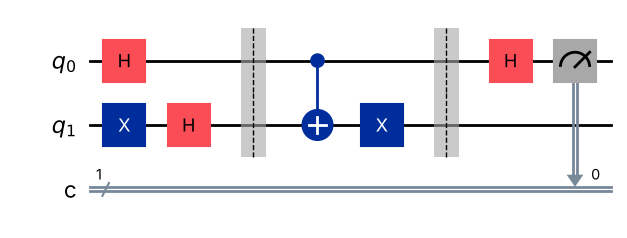

In [3]:
display(compile_circuit(deutsch_function(3)).draw(output="mpl"))

## Deutsch-Jozsa

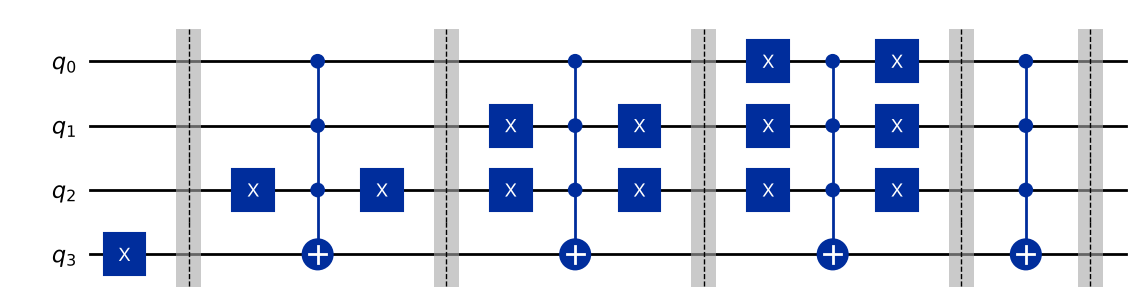

'balanced'

In [4]:
f = dj_query(3)
display(f.draw("mpl"))
run_algorithm(f)

## Bernstein-Vazirani

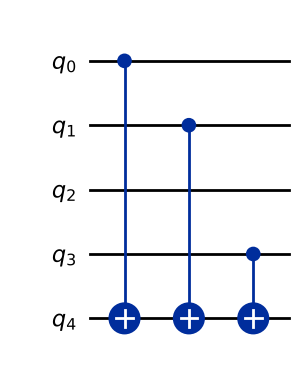

'0100'

In [5]:
display(bv_query("1011").draw(output="mpl"))
bv_algorithm(bv_query("0100"))

## Simon

┌───┐ ░                           ░ ┌───┐┌─┐      
q_0: ┤ H ├─░───■──────────────■────■───░─┤ H ├┤M├──────
     ├───┤ ░   │              │    │   ░ ├───┤└╥┘┌─┐   
q_1: ┤ H ├─░───┼────■─────────┼────┼───░─┤ H ├─╫─┤M├───
     ├───┤ ░   │    │         │    │   ░ ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├─░───┼────┼────■────┼────┼───░─┤ H ├─╫──╫─┤M├
     └───┘ ░ ┌─┴─┐  │    │  ┌─┴─┐  │   ░ └───┘ ║  ║ └╥┘
q_3: ──────░─┤ X ├──┼────┼──┤ X ├──┼───░───────╫──╫──╫─
           ░ └───┘┌─┴─┐  │  └───┘  │   ░       ║  ║  ║ 
q_4: ──────░──────┤ X ├──┼─────────┼───░───────╫──╫──╫─
           ░      └───┘┌─┴─┐     ┌─┴─┐ ░       ║  ║  ║ 
q_5: ──────░───────────┤ X ├─────┤ X ├─░───────╫──╫──╫─
           ░           └───┘     └───┘ ░       ║  ║  ║ 
c: 3/══════════════════════════════════════════╩══╩══╩═
                                               0  1  2

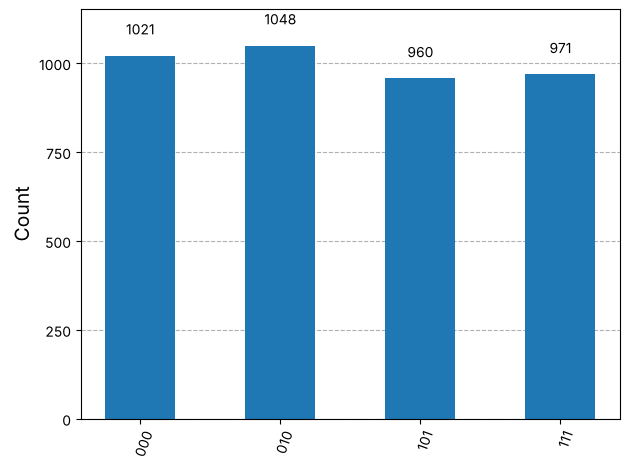

{'010': 1048, '000': 1021, '101': 960, '111': 971}


In [6]:
s = "101"
qc = simon_circuit(simon_query(s))
display(qc.draw())

counts = sample(qc, shots=4000)
display(plot_histogram(counts))
print(counts)

In [7]:
find_s(counts, 3)

['101']

Com poucas medidas a resposta fica ambígua:

In [8]:
find_s({'000': 1, '101': 1}, 3)

['010', '101', '111']